# Gold as a thermometer: temperature from the lattice parameter

An *equation of state* (EoS) describes how the unit-cell volume of a material changes with pressure and temperature, V = f(P, T).
It is usually used as a **pressure gauge**: a calibrant such as gold is mixed with the sample in a diamond anvil cell, and its lattice parameter gives the pressure.
The same EoS can be used the other way round, as a **thermometer**: at known pressure (here ambient), the lattice parameter of the calibrant gives the temperature.

In this tutorial we will:

1. read a series of lattice parameters of gold measured between room temperature and the melting point,
2. build the thermal equation of state of gold from Dorogokupets & Dewaele (2007),
3. compare the temperature deduced from the lattice parameter, $T_{EoS}$, with the experimental one, $T_{exp}$,
4. check whether using the first (room temperature) measurement as a reference improves the agreement.

In [1]:
%matplotlib inline
# `inline` is used to store the figures in the notebook for the documentation
import time
start_time = time.perf_counter()
import os
import numpy
from matplotlib.pyplot import subplots
from silx.resources import ExternalResources
from fabio.cbfimage import CIF
import pyFAI
from pyFAI.crystallography import EquationOfState, MieGruneisenDebye, Vinet
print(f"pyFAI version: {pyFAI.version}")

pyFAI version: 2026.11.0-dev0


## Experimental data

The lattice parameters of gold were measured by X-ray diffraction from 293 K to 1324 K, close to the melting point of gold (1337 K), by
I.-K. Suh, H. Ohta and Y. Waseda, *High-temperature thermal expansion of six metallic elements measured by dilatation method and X-ray diffraction*,
J. Mater. Sci. **23** (1988) 757-760, https://doi.org/10.1007/BF01174717.

They are available as 10 CIF files from the Crystallography Open Database (entries 9013035 to 9013044), gathered in an archive which is downloaded and extracted with `ExternalResources`.

In [2]:
downloader = ExternalResources("pyFAI", "http://www.silx.org/pub/pyFAI/", "PYFAI_DATA")
cif_files = sorted(f for f in downloader.getdir("Gold.tar.bz2") if f.endswith(".cif"))
print(f"{len(cif_files)} CIF files:", ", ".join(os.path.basename(f) for f in cif_files))

10 CIF files: 9013035.cif, 9013036.cif, 9013037.cif, 9013038.cif, 9013039.cif, 9013040.cif, 9013041.cif, 9013042.cif, 9013043.cif, 9013044.cif


Each CIF file contains the cell parameter `_cell_length_a` (in Å) and the temperature of the measurement `_diffrn_ambient_temperature` (in K).
They are read with the simple CIF parser of FabIO, which returns a dictionary of strings.

In [3]:
T_exp = []
cell_a = []
for filename in cif_files:
    cif = CIF(filename)
    T_exp.append(float(cif["_diffrn_ambient_temperature"]))
    cell_a.append(float(cif["_cell_length_a"]))
order = numpy.argsort(T_exp)
T_exp = numpy.array(T_exp)[order]
cell_a = numpy.array(cell_a)[order]
print("Reference: https://doi.org/" + cif["_journal_paper_doi"])
print("  T_exp (K)  a (Å)")
for t, a in zip(T_exp, cell_a):
    print(f"{t:9.0f}  {a:.3f}")

Reference: https://doi.org/10.1007/BF01174717
  T_exp (K)  a (Å)
      293  4.072
      574  4.091
      676  4.097
      777  4.103
      875  4.110
      971  4.117
     1075  4.125
     1179  4.134
     1280  4.141
     1324  4.145


Note that the lattice parameter is only given with 3 decimals: this limits the precision of the thermometer, as we will see.

## Equation of state of gold

Dorogokupets & Dewaele (2007) proposed internally consistent P-V-T equations of state for MgO, Au, Pt, NaCl-B1 and NaCl-B2:
P.I. Dorogokupets and A. Dewaele, *Equations of state of MgO, Au, Pt, NaCl-B1, and NaCl-B2: internally consistent high-temperature pressure scales*,
High Press. Res. **27** (2007) 431-446, https://doi.org/10.1080/08957950701659700.

The pressure is the sum of the room temperature isotherm (Vinet) and of the thermal pressure difference between T and the reference temperature $T_0$ = 298.15 K:

$$P(V,T) = P_{T_0}(V) + P_{th}(V,T) - P_{th}(V,T_0)$$

The thermal pressure is calculated with a Debye model, whose Debye temperature $\Theta$ depends on the volume through the Grüneisen parameter $\gamma$:

$$P_{th}(V,T) = \frac{\gamma}{V} 3 N k_B T D\left(\frac{\Theta}{T}\right) \qquad \gamma = \gamma_\infty + (\gamma_0 - \gamma_\infty) x^\beta \qquad x = V/V_0$$

This model is implemented in `pyFAI.crystallography.MieGruneisenDebye`, with the parameters of gold from table 1 of the publication.
The reference volume $V_0$ is not given in the publication: it comes from the data it is built on,
A. Dewaele, P. Loubeyre and M. Mezouar, Phys. Rev. B **70** (2004) 094112: 16.962 Å$^3$ per atom, i.e. 4 times this value for the cubic cell of gold.

In [4]:
eos = MieGruneisenDebye(Vinet(k0=167.0, k0p=5.90),
                        theta0=170, gamma0=2.89, gamma_inf=1.54, beta=4.36,
                        natoms=4, v0=4 * 16.962)
print(eos)
print(f"Lattice parameter at {eos.t0} K: {eos.v0 ** (1 / 3):.5f} Å")

MieGruneisenDebye(isothermal={'model': 'Vinet', 't0': 298.15, 'p0': 0.0, 'k0': 167.0, 'k0p': 5.9}, v0=67.848, t0=298.15, p0=0.0, theta0=170.0, gamma0=2.89, beta=4.36, natoms=4, gamma_inf=1.54, a=0.0, m=0.0, e=0.0, g=0.0)
Lattice parameter at 298.15 K: 4.07861 Å


In *thermometer* mode, the EoS provides the temperature at which the cell volume is reached, at a given pressure (here 0 GPa, ambient pressure).

In [5]:
T_eos = numpy.array([eos.temperature(volume=a ** 3, pressure=0.0) for a in cell_a])

To compare $T_{EoS}$ with $T_{exp}$, both are plotted against each other together with the identity line, and a linear regression is performed. A perfect thermometer would have a slope of 1 and an intercept of 0.

V0 from Dewaele (2004): T_EoS = 1.0171 T_exp -95.9 K; mean deviation -80.5 K, RMS 81.5 K


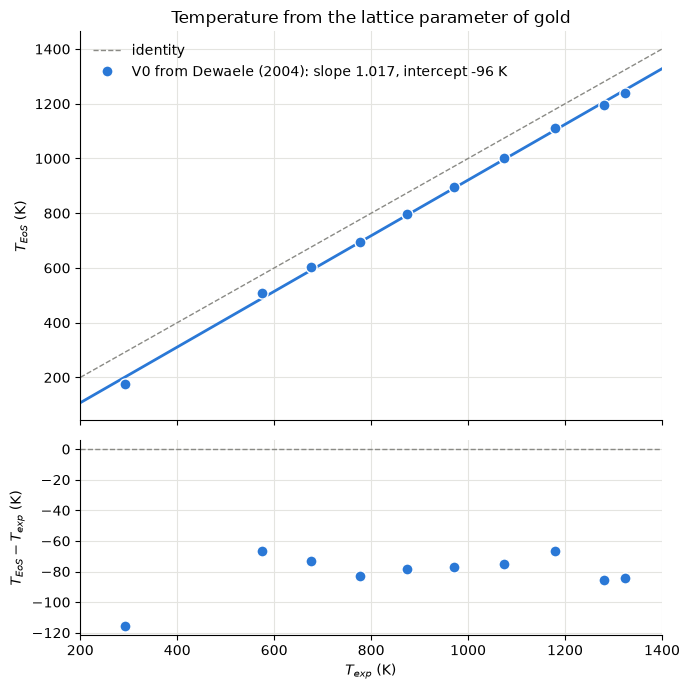

In [6]:
def regression(T_exp, T_eos, label):
    """Linear regression T_eos = slope * T_exp + intercept, and statistics of the residuals"""
    slope, intercept = numpy.polyfit(T_exp, T_eos, 1)
    residuals = T_eos - T_exp
    rms = numpy.sqrt(numpy.mean(residuals ** 2))
    print(f"{label}: T_EoS = {slope:.4f} T_exp {intercept:+.1f} K; "
          f"mean deviation {residuals.mean():+.1f} K, RMS {rms:.1f} K")
    return slope, intercept


def plot_thermometer(series):
    """Plot T_EoS vs T_exp (top) and the deviation T_EoS - T_exp (bottom) for several series

    :param series: list of 4-tuples (label, T_eos, color, marker)
    """
    fig, (ax, ax_res) = subplots(2, 1, figsize=(7, 7), sharex=True,
                                 gridspec_kw={"height_ratios": (2, 1)})
    span = numpy.array([200, 1400])
    ax.plot(span, span, color="#8a8a85", linewidth=1, linestyle="--", label="identity")
    ax_res.axhline(0, color="#8a8a85", linewidth=1, linestyle="--")
    for label, T_eos, color, marker in series:
        slope, intercept = regression(T_exp, T_eos, label)
        ax.plot(span, slope * span + intercept, color=color, linewidth=2)
        ax.plot(T_exp, T_eos, marker, color=color, markersize=8, markeredgecolor="white",
                label=f"{label}: slope {slope:.3f}, intercept {intercept:+.0f} K")
        ax_res.plot(T_exp, T_eos - T_exp, marker, color=color, markersize=8, markeredgecolor="white")
    ax.set_ylabel("$T_{EoS}$ (K)")
    ax.set_title("Temperature from the lattice parameter of gold")
    ax.legend(frameon=False)
    ax_res.set_xlabel("$T_{exp}$ (K)")
    ax_res.set_ylabel("$T_{EoS} - T_{exp}$ (K)")
    ax_res.set_xlim(*span)
    for axis in (ax, ax_res):
        axis.grid(color="#e4e4e0", linewidth=0.8)
        axis.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    return fig


fig = plot_thermometer([("V0 from Dewaele (2004)", T_eos, "#2a78d6", "o")])

The slope is close to 1: the thermal expansion predicted by the EoS matches the measured one.
But all temperatures are underestimated by about 100 K: the EoS gives a temperature well below 293 K for the first measurement.

This offset comes from the reference volume. The lattice parameter measured at 293 K, 4.072 Å, is 0.16% smaller than the one of the EoS at 298.15 K, 4.0786 Å.
This is a small difference for a pressure gauge, but a large one for a thermometer: the thermal expansion of gold is small, so a tiny error on the lattice parameter translates into a large error on the temperature.
The sensitivity of the thermometer can be evaluated from the EoS:

In [7]:
for T in (300.0, 1300.0):
    a = eos.volume(pressure=0.0, temperature=T) ** (1 / 3)
    dT = eos.temperature(volume=(a + 0.001) ** 3, pressure=0.0) - T
    print(f"At {T:.0f} K, an error of 0.001 Å on the lattice parameter shifts the temperature by {dT:.1f} K")

At 300 K, an error of 0.001 Å on the lattice parameter shifts the temperature by 17.6 K
At 1300 K, an error of 0.001 Å on the lattice parameter shifts the temperature by 10.6 K


The difference of 0.0066 Å between the two lattice parameters at room temperature thus explains the offset of about 100 K.
Such a systematic difference is common when comparing lattice parameters measured with different instruments, wavelength calibrations or samples.
Similarly, rounding the lattice parameter to 3 decimals, as in the CIF files, limits the resolution of the thermometer to ±9 K at room temperature and ±5 K at 1300 K.

## Using the room temperature measurement as a reference

The systematic error can be removed by measuring the calibrant at a known temperature, here the first point at 293 K, and by using it as the reference for the EoS:
the reference volume $V_0$ (at $T_0$ = 298.15 K) is chosen so that the EoS reproduces the measured volume at 293 K.
The shape of the EoS (bulk modulus, Grüneisen parameter, Debye temperature) is kept, only the absolute volume is calibrated.

In [8]:
T_ref, a_ref = T_exp[0], cell_a[0]
v0_ref = a_ref ** 3 / eos.volume_ratio(pressure=0.0, temperature=T_ref)
eos_ref = EquationOfState.from_dict({**eos.as_dict(), "v0": v0_ref})
print(f"Reference volume: {v0_ref:.3f} Å^3 (instead of {eos.v0:.3f} Å^3), a0 = {v0_ref ** (1 / 3):.5f} Å")
T_eos_ref = numpy.array([eos_ref.temperature(volume=a ** 3, pressure=0.0) for a in cell_a])

Reference volume: 67.533 Å^3 (instead of 67.848 Å^3), a0 = 4.07229 Å


V0 from Dewaele (2004): T_EoS = 1.0171 T_exp -95.9 K; mean deviation -80.5 K, RMS 81.5 K
V0 from the 293 K point: T_EoS = 0.9694 T_exp +32.1 K; mean deviation +4.6 K, RMS 15.6 K


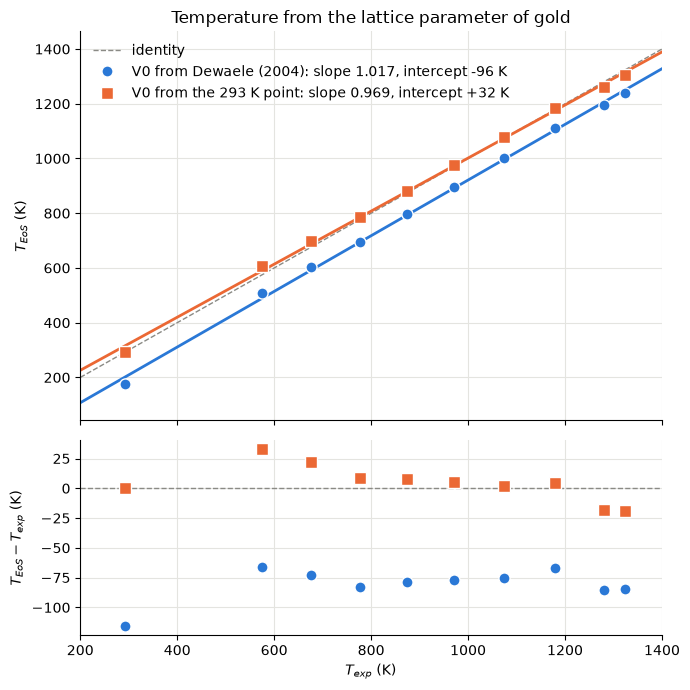

In [9]:
fig = plot_thermometer([("V0 from Dewaele (2004)", T_eos, "#2a78d6", "o"),
                        ("V0 from the 293 K point", T_eos_ref, "#eb6834", "s")])

Once the reference volume is calibrated on the room temperature measurement, the offset vanishes: the mean deviation drops from -80 K to +5 K and the RMS deviation from 82 K to 16 K over 1000 K.

The remaining deviations are larger than the rounding of the lattice parameters (±5 to ±9 K), and they are not random:

* the largest deviation, +33 K, is at 574 K; it decreases with temperature and stays between +2 K and +8 K from 777 K to 1179 K,
* the two last points, at 1280 K and 1324 K, are 20 K below the experimental temperature. They are within 60 K of the melting point of gold (1337 K), where anharmonic effects, not included in this model for gold, are expected to become important.

These two trends make the slope of the regression slightly lower than 1.

## Equation of state from a JCPDS card

The equation of state does not need to be typed in: pyFAI ships a set of JCPDS cards (version 4, the format used by Dioptas and at many high-pressure beamlines) in its resources, for gold, platinum, NaCl and neon, from several publications.

In [10]:
from pyFAI.resources import resource_filename
from pyFAI.io.calibrant_config import CalibrantConfig
eos_dir = resource_filename("EoS")
print("\n".join(sorted(f for f in os.listdir(eos_dir) if f.endswith(".jcpds"))))

Au_BM3_Fei2007.jcpds
Au_Vinet_Dorogokupets2007.jcpds
Au_Vinet_Fei2007.jcpds
Au_Vinet_Tsuchiya2003.jcpds
Au_Vinet_Ye2017.jcpds
NaCl-B1_Vinet_Dorogokupets2007.jcpds
NaCl-B2_BM3_Fei2007.jcpds
NaCl-B2_Vinet_Dorogokupets2007.jcpds
NaCl-B2_Vinet_Fei2007.jcpds
Ne_BM3_Fei2007.jcpds
Ne_Vinet_Fei2007.jcpds
Pt_BM3_Fei2007.jcpds
Pt_Vinet_Dorogokupets2007.jcpds
Pt_Vinet_Fei2007.jcpds
Pt_Vinet_Ye2017.jcpds


A JCPDS card is read with `CalibrantConfig.from_JCPDS`. Besides the cell and the reflections, it provides the equation of state in its `eos` attribute: an isothermal compression model (Vinet or Birch-Murnaghan) combined with a polynomial thermal expansion, in a `PVT` object.
The thermal expansion of a JCPDS card is the polynomial $V_0(T) = V_0 [1 + \alpha_T (T-T_0) + \alpha'_T (T-T_0)^2]$, while the bulk modulus and its derivative vary linearly with temperature.
This is only an approximation of the Mie-Grüneisen-Debye models of the publications: in the cards shipped with pyFAI, these coefficients have been fitted on the original model at ambient pressure between 298 K and 1000 K, as explained in their comments.

Two cards of gold are compared here:

* `Au_Vinet_Dorogokupets2007.jcpds`, the approximation of the model used above,
* `Au_Vinet_Fei2007.jcpds`, from Y. Fei *et al.*, PNAS **104** (2007) 9182, https://doi.org/10.1073/pnas.0609013104, an independent Mie-Grüneisen-Debye model of gold.

In [11]:
cards = {}
for name in ("Au_Vinet_Dorogokupets2007", "Au_Vinet_Fei2007"):
    config = CalibrantConfig.from_JCPDS(os.path.join(eos_dir, name + ".jcpds"))
    cards[name] = config.eos
    print(f"{name}: a = {config.to_cell().a:.5f} Å")
    print(f"   {config.eos}")

Au_Vinet_Dorogokupets2007: a = 4.07861 Å
   PVT(isothermal={'model': 'Vinet', 't0': 298.15, 'p0': 0.0, 'k0': 167.0, 'k0p': 5.9}, thermal={'model': 'volume-expansion', 't0': 298.15, 'p0': 0.0, 'coefficients': [4.1103e-05, 1.1328e-08]}, dk0dt=-0.052158, dk0pdt=0.0012577, t0=298.15, p0=0.0, v0=67.84792015821839)
Au_Vinet_Fei2007: a = 4.07865 Å
   PVT(isothermal={'model': 'Vinet', 't0': 298.15, 'p0': 0.0, 'k0': 167.0, 'k0p': 6.0}, thermal={'model': 'volume-expansion', 't0': 298.15, 'p0': 0.0, 'coefficients': [4.2682e-05, 7.4624e-09]}, dk0dt=-0.041264, dk0pdt=0.0004556, t0=298.15, p0=0.0, v0=67.84991638493962)


As in the previous section, the reference volume of each card is calibrated on the measurement at 293 K, before converting the lattice parameters into temperatures.

In [12]:
def calibrate(eos, a_ref, T_ref):
    """Return a copy of the EoS whose reference volume matches the lattice parameter a_ref measured at T_ref, at ambient pressure"""
    v0 = a_ref ** 3 / eos.volume_ratio(pressure=0.0, temperature=T_ref)
    return EquationOfState.from_dict({**eos.as_dict(), "v0": v0})


T_cards = {}
for name, card in cards.items():
    calibrated = calibrate(card, a_ref, T_ref)
    T_cards[name] = numpy.array([calibrated.temperature(volume=a ** 3, pressure=0.0) for a in cell_a])

difference = T_cards["Au_Vinet_Dorogokupets2007"] - T_eos_ref
print("Difference between the JCPDS card and the full model of Dorogokupets & Dewaele (K):")
for t, d in zip(T_exp, difference):
    print(f"{t:6.0f} K: {d:+6.1f}")

Difference between the JCPDS card and the full model of Dorogokupets & Dewaele (K):
   293 K:   -0.0
   574 K:   +1.7
   676 K:   +1.5
   777 K:   +1.6
   875 K:   +2.4
   971 K:   +4.2
  1075 K:   +7.8
  1179 K:  +14.2
  1280 K:  +21.2
  1324 K:  +25.9


Dorogokupets, full model: T_EoS = 0.9694 T_exp +32.1 K; mean deviation +4.6 K, RMS 15.6 K
Dorogokupets, JCPDS card: T_EoS = 0.9933 T_exp +18.6 K; mean deviation +12.6 K, RMS 15.9 K
Fei, JCPDS card: T_EoS = 1.0399 T_exp -8.1 K; mean deviation +27.9 K, RMS 31.7 K


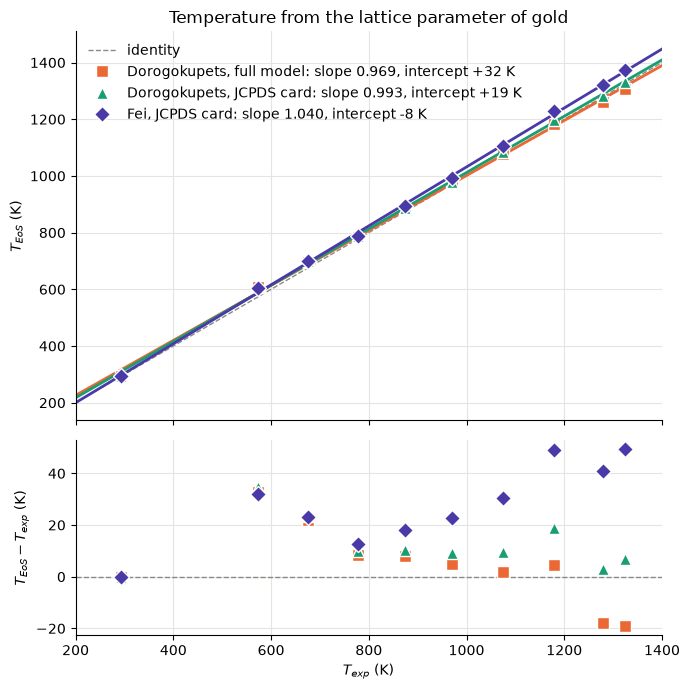

In [13]:
fig = plot_thermometer([("Dorogokupets, full model", T_eos_ref, "#eb6834", "s"),
                        ("Dorogokupets, JCPDS card", T_cards["Au_Vinet_Dorogokupets2007"], "#199e70", "^"),
                        ("Fei, JCPDS card", T_cards["Au_Vinet_Fei2007"], "#4a3aa7", "D")])

* The JCPDS card of Dorogokupets & Dewaele follows the full model within a few kelvin up to 1000 K, the range over which its coefficients were fitted.
  Above, the polynomial expansion is extrapolated and departs from the full model, by 26 K at 1324 K.
  The full model should be preferred when the temperature exceeds the validity range of the card.
* The model of Fei *et al.* predicts a smaller thermal expansion of gold at high temperature: the temperatures deduced from its JCPDS card are too high, by up to 50 K above 1100 K, and the slope of the regression is 1.04.
  About 10 K of this deviation comes from the extrapolation of the card above 1000 K: the full model of Fei *et al.* (`MieGruneisenDebye` with `gamma_inf=0` and `beta=q`) overestimates the temperature by up to 40 K, with a slope of 1.03.
  Dorogokupets & Dewaele pointed out that the volume dependence of the Grüneisen parameter used by Fei *et al.* (q = 0.6 for gold) leads to a poor description of the thermodynamic properties of gold at high temperature.

## Conclusion

The thermal equation of state of gold can be used as a thermometer, at ambient pressure as well as at high pressure, with `EquationOfState.temperature`.
Its accuracy is governed by the knowledge of the reference lattice parameter: a systematic error of 0.001 Å on the lattice parameter shifts the temperature by about 18 K at room temperature and 11 K at 1300 K.
Measuring the calibrant at a known temperature, and using this measurement as the reference of the EoS, removes this systematic error: in this example, the temperature is then recovered with an RMS deviation of 16 K from room temperature up to the vicinity of the melting point.

The equations of state can be built from their parameters, or read from the JCPDS cards shipped with pyFAI with `CalibrantConfig.from_JCPDS`.
JCPDS cards only approximate the thermal behaviour of the calibrant: check the comments of the card for the range over which this approximation holds, and the publication the card comes from.

In [14]:
print(f"Total execution time: {time.perf_counter() - start_time:.3f} s")

Total execution time: 2.526 s
